### weighted sampler approach

In [36]:
from pathlib import Path
import sys

def find_project_root():
    here = Path.cwd()
    for p in [here, *here.parents]:
        if (p / "utils").exists() and (p / "models").exists():
            return p
    for p in [here, *here.parents]:
        if any((p / m).exists() for m in (".git", "requirements.txt", "pyproject.toml")):
            return p
    return here

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [37]:
# Import necessary libraries
import os
import sys
import matplotlib.pyplot as plt
import torch
import numpy as np
import torch.nn as nn
import pandas as pd
from utils.reproducibility_utils import seed_everything
from utils.smogn_data_loader import load_data_weighted

# Set the plotting style for better-looking visualizations
plt.style.use('seaborn-v0_8')

In [38]:
# --- EXECUTION ---
train_dataloader, val_dataloader, pipeline = load_data_weighted(
    train_path = "../../datasets_challenge/train",
    train_ratio = 0.98,  # 🔥 FIX: Was None! Must be 0.98 for 98/2 split
    batchsize = 64,
    columns_to_drop = ["sideSlip", "vyCG", "time", "longitude","latitude"],
    sequence_length = 20,
    threshold = True,
    threshold_value = 3.0,
    threshold_column = "vxCG",
    target = "sideSlip",
    scaling = True,
    seed = 42,
)

print(f"✅ Weighted DataLoader ready. Train samples: {len(train_dataloader.dataset)}")

Calculating weights for few-shot drift events...
✅ Weighted DataLoader ready. Train samples: 134338


C:\Users\Jobel Jose George\AppData\Local\Temp\ipykernel_17840\1243472795.py:7: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



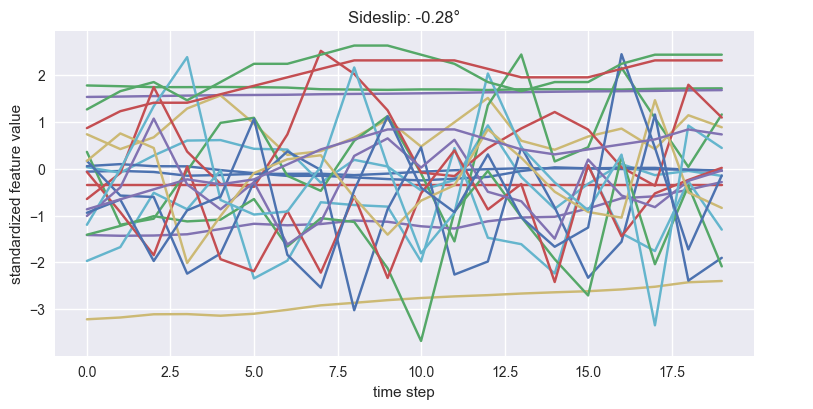

In [39]:
# Get one batch to check dimensions
X, y = next(iter(train_dataloader))

plt.figure(figsize=(8,4))
plt.plot(X[0,:,:].cpu().numpy())
plt.title("Sideslip: "+str(round(y[0].item(),2))+"°")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small')
plt.tight_layout()
plt.xlabel("time step")
plt.ylabel("standardized feature value")
plt.show()

In [40]:
class RNN(nn.Module):
    def __init__(self, input_size, output_size=1, rnn_units=28, fc_units=28, 
                 activation_fct=nn.ReLU(), dropout=[0.0, 0, 0], rnn_nonlinearity='relu'):
        super(RNN, self).__init__()
        
        self.rnn_layer = nn.RNN(input_size=input_size, hidden_size=rnn_units, 
                                num_layers=1, nonlinearity=rnn_nonlinearity, batch_first=True)
        
        self.fc = nn.Linear(rnn_units, fc_units)
        self.output_layer = nn.Linear(fc_units, output_size)
        
        self.dropout1 = nn.Dropout(dropout[0])
        self.dropout2 = nn.Dropout(dropout[1])
        self.dropout3 = nn.Dropout(dropout[2])
        
        self.activation_fct = activation_fct
 
    def forward(self, x):
        x = self.dropout1(x)
        x, _ = self.rnn_layer(x)
        x = x[:, -1, :]
        x = self.dropout2(x)
        x = self.activation_fct(self.fc(x))
        x = self.dropout3(x)
        x = self.output_layer(x)
        return x

In [41]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

input_size = X.shape[2]
rnn_units = 64
fc_units = 64
output_size = 1
lr = 0.0003

model = RNN(
    input_size=input_size, 
    output_size=output_size,
    rnn_units=rnn_units,
    fc_units=fc_units,
    dropout=[0.0, 0.0, 0.0]
).to(device)

criterion = nn.HuberLoss(delta=1.0)
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")

Using device: cpu
Model parameters: 9,857


In [42]:
import torch
import numpy as np

num_epochs = 100

for epoch in range(num_epochs):
    model.train()
    train_losses = []
    
    for batch_idx, (data, target) in enumerate(train_dataloader):
        data, target = data.to(device), target.to(device)
        
        # RNN expects (Batch, Seq, Features) -> your data loader should provide this
        optimizer.zero_grad()
        output = model(data)
        
        # Flatten target if necessary (depends on your dataset shape)
        loss = criterion(output.squeeze(), target.squeeze())
        
        loss.backward()
        optimizer.step()
        
        train_losses.append(loss.item())

    # --- Validation Phase ---
    model.eval()
    val_losses = []
    drift_errors = [] # Errors where sideSlip > 2 degrees (Few-Shot)
    stable_errors = [] # Errors where sideSlip < 2 degrees (Many-Shot)

    with torch.no_grad():
        for data, target in val_dataloader:
            data, target = data.to(device), target.to(device)
            output = model(data).squeeze()
            target = target.squeeze()
            
            # Global Loss
            val_loss = criterion(output, target)
            val_losses.append(val_loss.item())
            
            # Split errors to monitor "Few-Shot" performance
            mask_drift = torch.abs(target) > 2.0  # Threshold for drift
            mask_stable = torch.abs(target) <= 2.0
            
            if mask_drift.any():
                drift_err = torch.abs(output[mask_drift] - target[mask_drift]).mean()
                drift_errors.append(drift_err.item())
            if mask_stable.any():
                stable_err = torch.abs(output[mask_stable] - target[mask_stable]).mean()
                stable_errors.append(stable_err.item())

    print(f"Epoch {epoch+1}/{num_epochs}")
    print(f"Train Loss: {np.mean(train_losses):.4f} | Val Loss: {np.mean(val_losses):.4f}")
    if drift_errors:
        print(f"⚠️ Drift MAE (Few-Shot): {np.mean(drift_errors):.4f}")
    print(f"✅ Stable MAE (Many-Shot): {np.mean(stable_errors):.4f}")
    print("-" * 30)

Epoch 1/100
Train Loss: 0.3352 | Val Loss: 0.0803
⚠️ Drift MAE (Few-Shot): 0.4113
✅ Stable MAE (Many-Shot): 0.2845
------------------------------
Epoch 2/100
Train Loss: 0.0706 | Val Loss: 0.0749
⚠️ Drift MAE (Few-Shot): 0.3927
✅ Stable MAE (Many-Shot): 0.2753
------------------------------
Epoch 3/100
Train Loss: 0.0565 | Val Loss: 0.0623
⚠️ Drift MAE (Few-Shot): 0.3276
✅ Stable MAE (Many-Shot): 0.2520
------------------------------
Epoch 4/100
Train Loss: 0.0485 | Val Loss: 0.0692
⚠️ Drift MAE (Few-Shot): 0.3274
✅ Stable MAE (Many-Shot): 0.2608
------------------------------
Epoch 5/100
Train Loss: 0.0429 | Val Loss: 0.0543
⚠️ Drift MAE (Few-Shot): 0.2833
✅ Stable MAE (Many-Shot): 0.2256
------------------------------
Epoch 6/100
Train Loss: 0.0389 | Val Loss: 0.0587
⚠️ Drift MAE (Few-Shot): 0.2681
✅ Stable MAE (Many-Shot): 0.2363
------------------------------
Epoch 7/100
Train Loss: 0.0312 | Val Loss: 0.0430
⚠️ Drift MAE (Few-Shot): 0.2672
✅ Stable MAE (Many-Shot): 0.2106
---------

In [43]:
from utils.data_loading import load_data, load_test_data, feature_names

In [44]:
# Load complete training data for visualization
train_dataloader_unshuffled = load_test_data(
    test_path="../../datasets_challenge/train",
    batchsize=64,
    pipeline=pipeline,
    load_anonymized_data=False
)

../../datasets_challenge/train\train_part_001.csv
../../datasets_challenge/train\train_part_002.csv
../../datasets_challenge/train\train_part_003.csv
../../datasets_challenge/train\train_part_004.csv
../../datasets_challenge/train\train_part_005.csv
../../datasets_challenge/train\train_part_006.csv
../../datasets_challenge/train\train_part_007.csv
../../datasets_challenge/train\train_part_008.csv
../../datasets_challenge/train\train_part_009.csv
../../datasets_challenge/train\train_part_010.csv
../../datasets_challenge/train\train_part_011.csv
../../datasets_challenge/train\train_part_012.csv
../../datasets_challenge/train\train_part_013.csv
../../datasets_challenge/train\train_part_014.csv
../../datasets_challenge/train\train_part_015.csv
../../datasets_challenge/train\train_part_016.csv
../../datasets_challenge/train\train_part_017.csv
../../datasets_challenge/train\train_part_018.csv
../../datasets_challenge/train\train_part_019.csv
../../datasets_challenge/train\train_part_020.csv


In [45]:
import plotly.graph_objects as go

model.eval()
total_loss = 0
preds = []
ground_truths = []

with torch.no_grad():
    for step, (x, y) in enumerate(train_dataloader_unshuffled):
        X, y = x.to(device), y.to(device).reshape([len(y), 1])
        pred = model(X)
        loss = criterion(pred, y)
        total_loss += loss.item()
        preds.append(pred.reshape(-1).cpu().numpy())
        ground_truths.append(y.reshape(-1).cpu().numpy())

    print(f"Training set MAE: {total_loss/(step+1):.5f}")
    
    ground_truths = np.concatenate(ground_truths)
    preds = np.concatenate(preds)

fig = go.Figure()
fig.add_trace(go.Scatter(y=ground_truths, mode='lines', name='truth', line=dict(color='blue')))
fig.add_trace(go.Scatter(y=preds.flatten(), mode='lines', name='pred', line=dict(color='red'), opacity=0.8))
fig.update_layout(
    title='Ground Truth vs Predictions (Training Set)',
    xaxis_title='Sample Index',
    yaxis_title='Sideslip Angle (degrees)',
    width=1200,
    height=500
)
fig.show()



Training set MAE: 0.01932


In [ ]:
print("\nLoading test data...")
test_dataloader = load_test_data(
    test_path = "../../datasets_challenge/test",
    batchsize = 64,
    pipeline = pipeline, 
    load_anonymized_data=True
)


Loading test data...
../../datasets_challenge/test\test_part_001.csv
../../datasets_challenge/test\test_part_002.csv
../../datasets_challenge/test\test_part_003.csv
../../datasets_challenge/test\test_part_004.csv
../../datasets_challenge/test\test_part_005.csv
../../datasets_challenge/test\test_part_006.csv
../../datasets_challenge/test\test_part_007.csv
../../datasets_challenge/test\test_part_008.csv
../../datasets_challenge/test\test_part_009.csv
../../datasets_challenge/test\test_part_010.csv
../../datasets_challenge/test\test_part_011.csv


In [47]:
# Generate test predictions
model.eval()
test_preds = []

with torch.no_grad():
    for step, (x, y) in enumerate(test_dataloader):
        X = x.to(device)
        pred = model(X)
        test_preds.append(pred.reshape(-1).cpu().numpy())

test_preds = np.concatenate(test_preds)
print(f"Test predictions: {len(test_preds)} samples")
print(f"Range: [{test_preds.min():.3f}, {test_preds.max():.3f}]")
print(f"Mean:  {test_preds.mean():.3f}")
print(f"Std:   {test_preds.std():.3f}")

Test predictions: 49328 samples
Range: [-9.522, 9.771]
Mean:  0.001
Std:   1.502


In [49]:
import numpy as np

# 1. Choose a window size
# If your data is 100Hz, a window of 5-10 samples is usually safe.
# Too small = still noisy. Too large = you lose the peaks of the drift.
window_size = 5 

def moving_average(data, window_size):
    # This pads the data so the output length remains the same
    return np.convolve(data, np.ones(window_size)/window_size, mode='same')

# 2. Apply the smoothing
test_preds_smoothed = moving_average(test_preds, window_size)

# 3. Save the smoothed version
y_pred_smoothed = pd.DataFrame({
    "id": range(len(test_preds_smoothed)),
    "predicted_sideslip": test_preds_smoothed
})

y_pred_smoothed.to_csv("predictions_weighted_smoothed.csv", index=False)

In [50]:
# Save predictions
y_pred = pd.DataFrame({
    "id": range(len(test_preds)),
    "predicted_sideslip": test_preds
})

y_pred.to_csv("predictions_weighted_sampler2.csv", index=False)

print(f"\n" + "="*80)
print(f"✅ Predictions saved to 'predictions_weighted_sampler2.csv'")
print(f"   Total samples: {len(test_preds)}")
print(f"   Ready for Kaggle submission!")
print("="*80)


✅ Predictions saved to 'predictions_weighted_sampler2.csv'
   Total samples: 49328
   Ready for Kaggle submission!
